In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [4]:
df = pd.read_csv("data/synthetic_daily_data.csv", parse_dates=["date"])
df.head()

,date,day_of_week,week,low_demand_day,off_task,demand_refusal,elopement,unsafe_physical,points_possible,points_earned,g10_opps,g10_correct,g11_opps,g11_correct,g12_opps,g12_correct,narrative_note
0,2025-09-02,Tuesday,1,No,10,6,1,1,20,8,4,1,8,2,5,2,Typical day. Off-task behavior was frequent; r...
1,2025-09-03,Wednesday,1,No,17,5,3,2,20,9,6,2,8,4,7,2,Participated briefly with the group before req...
2,2025-09-04,Thursday,1,No,16,5,2,2,20,11,6,2,4,1,8,2,Typical day. Off-task behavior was frequent; r...
3,2025-09-05,Friday,1,No,15,8,3,1,20,7,5,3,8,3,8,3,Verbal refusal during math. Chose a movement b...
4,2025-09-08,Monday,1,Yes,7,4,1,0,20,13,7,3,8,5,7,3,Low demand day. Mostly engaged in preferred ac...


/var/folders/5q/qfsqk32s56q5bny3cywlgym00000gn/T/ipykernel_52814/2074902415.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  scatter.set_xticklabels(scatter.get_xticklabels(), rotation=45)
/var/folders/5q/qfsqk32s56q5bny3cywlgym00000gn/T/ipykernel_52814/2074902415.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  scatter.set_xticklabels(scatter.get_xticklabels(), fontsize=8)


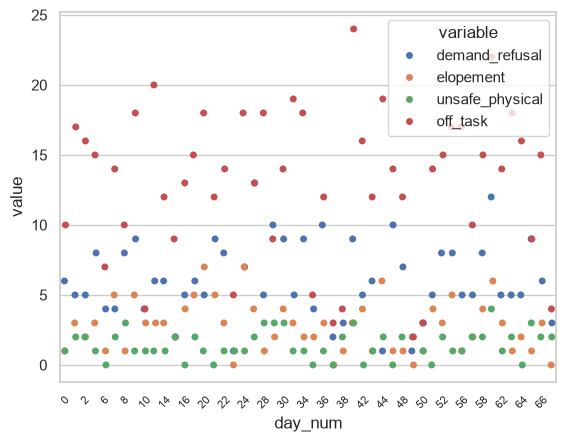

In [28]:
df["day_num"] = (df["date"] - df["date"].min()).dt.days

df_wide = df.melt(id_vars="day_num", value_vars=["demand_refusal", "elopement", "unsafe_physical", "off_task"])

scatter = sns.stripplot(data=df_wide, 
              x="day_num",
              y="value",
              hue="variable")

scatter.set_xticklabels(scatter.get_xticklabels(), rotation=45)
scatter.set_xticklabels(scatter.get_xticklabels(), fontsize=8)

# scatter x-axis labels
for ind, label in enumerate(scatter.get_xticklabels()):
    if ind % 2 == 0:
        label.set_visible(True)
    else:
        label.set_visible(False)   
